In [678]:
import pandas as pd
import copy

In [679]:
!ls

0bf8bc6e-30d0-4c50-956a-603fc693d966.csv  sample_data
4910797b-ee55-40a7-8668-10efd5c1b960.csv


In [680]:
labels = pd.read_csv('0bf8bc6e-30d0-4c50-956a-603fc693d966.csv')
data = pd.read_csv('4910797b-ee55-40a7-8668-10efd5c1b960.csv')

In [681]:
data['id'].value_counts().max()

1

In [682]:
drop_columns = []

In [683]:
data

,id,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,...,payment_type,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group
0,69572,6000.0,2011-03-14,Roman,1390,Roman,34.938093,-9.856322,none,0,...,annually,soft,good,enough,enough,spring,spring,groundwater,communal standpipe,communal standpipe
1,8776,0.0,2013-03-06,Grumeti,1399,GRUMETI,34.698766,-2.147466,Zahanati,0,...,never pay,soft,good,insufficient,insufficient,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe
2,34310,25.0,2013-02-25,Lottery Club,686,World vision,37.460664,-3.821329,Kwa Mahundi,0,...,per bucket,soft,good,enough,enough,dam,dam,surface,communal standpipe multiple,communal standpipe
3,67743,0.0,2013-01-28,Unicef,263,UNICEF,38.486161,-11.155298,Zahanati Ya Nanyumbu,0,...,never pay,soft,good,dry,dry,machine dbh,borehole,groundwater,communal standpipe multiple,communal standpipe
4,19728,0.0,2011-07-13,Action In A,0,Artisan,31.130847,-1.825359,Shuleni,0,...,never pay,soft,good,seasonal,seasonal,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59395,60739,10.0,2013-05-03,Germany Republi,1210,CES,37.169807,-3.253847,Area Three Namba 27,0,...,per bucket,soft,good,enough,enough,spring,spring,groundwater,communal standpipe,communal standpipe
59396,27263,4700.0,2011-05-07,Cefa-njombe,1212,Cefa,35.249991,-9.070629,Kwa Yahona Kuvala,0,...,annually,soft,good,enough,enough,river,river/lake,surface,communal standpipe,communal standpipe
59397,37057,0.0,2011-04-11,NaN,0,NaN,34.017087,-8.750434,Mashine,0,...,monthly,fluoride,fluoride,enough,enough,machine dbh,borehole,groundwater,hand pump,hand pump
59398,31282,0.0,2011-03-08,Malec,0,Musa,35.861315,-6.378573,Mshoro,0,...,never pay,soft,good,insufficient,insufficient,shallow well,shallow well,groundwater,hand pump,hand pump


In [684]:
#data['long_lat'] = data.apply(
#    lambda col : str(col['longitude']) + '_' + str(col['latitude']),
#    axis = 1
#)

In [685]:
#(data['long_lat'].value_counts() == 2).sum()

In [686]:
#data[data['long_lat'] == data['long_lat'].value_counts().reset_index()['long_lat'][1]]

In [687]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59400 entries, 0 to 59399
Data columns (total 40 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     59400 non-null  int64  
 1   amount_tsh             59400 non-null  float64
 2   date_recorded          59400 non-null  object 
 3   funder                 55763 non-null  object 
 4   gps_height             59400 non-null  int64  
 5   installer              55745 non-null  object 
 6   longitude              59400 non-null  float64
 7   latitude               59400 non-null  float64
 8   wpt_name               59398 non-null  object 
 9   num_private            59400 non-null  int64  
 10  basin                  59400 non-null  object 
 11  subvillage             59029 non-null  object 
 12  region                 59400 non-null  object 
 13  region_code            59400 non-null  int64  
 14  district_code          59400 non-null  int64  
 15  lg

In [688]:
data[data['quantity'] != data['quantity_group']]

,id,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,...,payment_type,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group


In [689]:
drop_columns.append('quantity_group')

In [690]:
data[data['waterpoint_type'] != data['waterpoint_type_group']][['waterpoint_type', 'waterpoint_type_group']]['waterpoint_type_group'].value_counts()

,count
waterpoint_type_group,
communal standpipe,6103


In [691]:
data[data['waterpoint_type'] != data['waterpoint_type_group']][['waterpoint_type', 'waterpoint_type_group']]['waterpoint_type'].value_counts()

,count
waterpoint_type,
communal standpipe multiple,6103


In [692]:
data.apply(
    lambda col : len(col.unique())
)

,0
id,59400
amount_tsh,98
date_recorded,356
funder,1897
gps_height,2428
installer,2146
longitude,57516
latitude,57517
wpt_name,37400
num_private,65


In [693]:
printna = lambda : data.isna().sum().sort_values()[data.isna().sum().sort_values() > 0]
printna()

,0
wpt_name,2
subvillage,371
permit,3056
public_meeting,3334
funder,3637
installer,3655
scheme_management,3878
scheme_name,28810


In [694]:
data['wpt_name'][data['wpt_name'].isna()] = 'none'

/tmp/ipykernel_75876/2036743347.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  data['wpt_name'][data['wpt_name'].isna()] = 'none'
/tmp/ipykernel_75876/2036743347.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a 

In [695]:
printna()

,0
subvillage,371
permit,3056
public_meeting,3334
funder,3637
installer,3655
scheme_management,3878
scheme_name,28810


In [696]:
data[data['subvillage'].isna()][['longitude', 'latitude', 'water_quality']]

,longitude,latitude,water_quality
342,36.557631,-6.233394,soft
360,36.416701,-6.220157,soft
379,36.729383,-6.084255,salty
565,36.696881,-5.993192,salty
966,36.322623,-6.030500,salty
...,...,...,...
59008,36.770490,-6.288555,soft
59091,36.407974,-5.715084,salty
59105,36.889359,-5.959966,salty
59215,36.854216,-6.010508,salty


In [697]:
data['water_quality'].value_counts()

,count
water_quality,
soft,50818
salty,4856
unknown,1876
milky,804
coloured,490
salty abandoned,339
fluoride,200
fluoride abandoned,17


In [698]:
import numpy as np
from sklearn.neighbors import BallTree

def count_nearby_wells(df, radius_km=20):
    # BallTree expects [latitude, longitude] in radians
    coords = np.radians(df[['latitude', 'longitude']].to_numpy())

    tree = BallTree(coords, metric='haversine')

    # Convert kilometers to radians
    radius_rad = radius_km / 6371.0

    # Count wells within radius
    counts = tree.query_radius(coords, r=radius_rad, count_only=True)

    # Subtract 1 to exclude the well itself
    return counts - 1

for km in [3,5,10,20]:
    label = f'nearby_wells_{str(km)}km'

    data[label] = np.nan

    valid = data[['latitude', 'longitude']].notna().all(axis=1)

    data.loc[valid, label] = count_nearby_wells(
        data.loc[valid],
        radius_km=km
    )

<Axes: xlabel='nearby_wells_3km'>

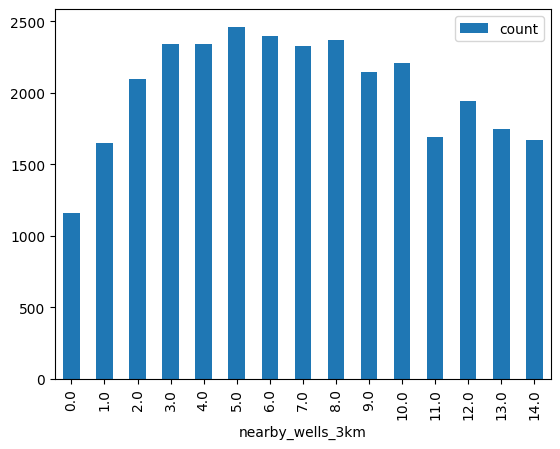

In [699]:
data['nearby_wells_3km'].value_counts().reset_index().sort_values(by='nearby_wells_3km').set_index('nearby_wells_3km').iloc[:15].plot(kind='bar')

<Axes: xlabel='nearby_wells_5km'>

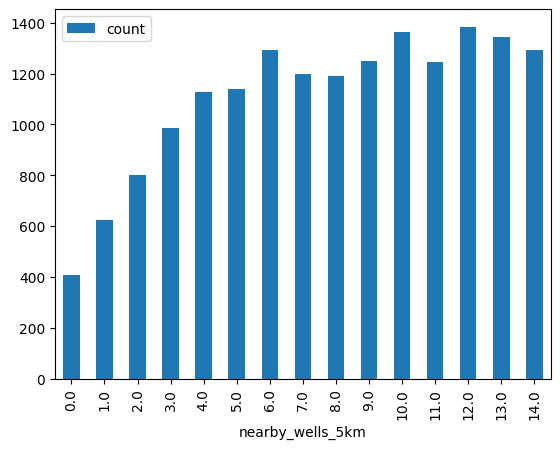

In [700]:
data['nearby_wells_5km'].value_counts().reset_index().sort_values(by='nearby_wells_5km').set_index('nearby_wells_5km').iloc[:15].plot(kind='bar')

<Axes: xlabel='nearby_wells_10km'>

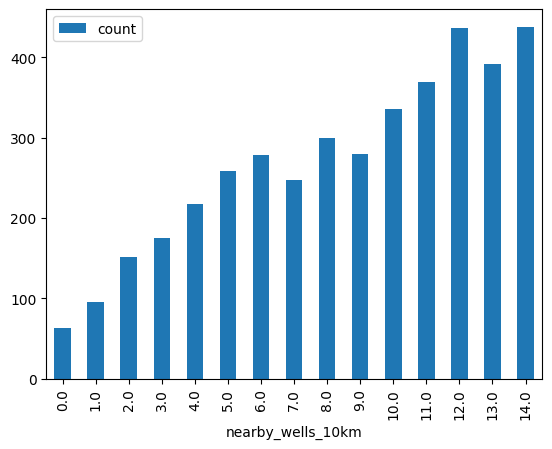

In [701]:
data['nearby_wells_10km'].value_counts().reset_index().sort_values(by='nearby_wells_10km').set_index('nearby_wells_10km').iloc[:15].plot(kind='bar')

<Axes: xlabel='nearby_wells_20km'>

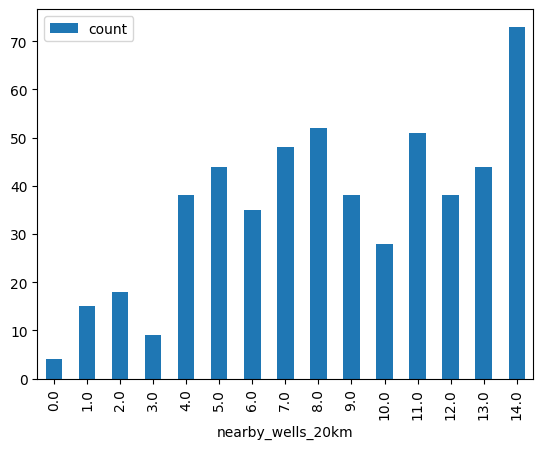

In [702]:
data['nearby_wells_20km'].value_counts().reset_index().sort_values(by='nearby_wells_20km').set_index('nearby_wells_20km').iloc[:15].plot(kind='bar')

In [703]:
data.id.nunique(), data.shape

(59400, (59400, 44))

In [704]:
drop_columns.append('id')

In [705]:
data = pd.merge(left=data, right=labels, on='id', how='left', validate='many_to_one')

In [706]:
data['status_group'].isna().sum()

np.int64(0)

In [707]:
(data['construction_year'] == 0).sum()

np.int64(20709)

# Feature engineering: Age

In [708]:
data["date_recorded"] = pd.to_datetime(data["date_recorded"])

data["well_age"] = (
    data["date_recorded"].dt.year
    - data["construction_year"]
)

data.loc[
    (data["construction_year"] == 0) |
    (data["well_age"] < 0),
    "well_age"
] = np.nan

In [709]:
import numpy as np
from sklearn.impute import SimpleImputer

# Identify missing construction years
data["construction_year_missing"] = (
    data["construction_year"] == 0
).astype(int)

# Treat zero as missing
data["construction_year"] = data["construction_year"].replace(0, np.nan)

# Fixing missing values
- We cannot afford to systematically drop rows based on missing data, since this in effect would ignore certain wells in production.
- Instead, we fill it to the best of our abilities

In [710]:
data.isna().sum()[data.isna().sum() > 0]

,0
funder,3637
installer,3655
subvillage,371
public_meeting,3334
scheme_management,3878
scheme_name,28810
permit,3056
construction_year,20709
well_age,20718


# Funder

In [711]:
data['funder'].value_counts()[:15]

,count
funder,
Government Of Tanzania,9084
Danida,3114
Hesawa,2202
Rwssp,1374
World Bank,1349
Kkkt,1287
World Vision,1246
Unicef,1057
Tasaf,877


We see that there are already four rows with the 'Unknown' installer value.
We follow this naming convention and fill the missing values with 'Unknown'.

In [712]:
(data['funder'] == 'Unknown').sum()

np.int64(4)

In [713]:
def fill_unknown_funders(funder_series):
    return funder_series.apply(
        lambda val : 'Unknown' if pd.isna(val) else val
    )

fill_unknown_funders(data['funder'])

,funder
0,Roman
1,Grumeti
2,Lottery Club
3,Unicef
4,Action In A
...,...
59395,Germany Republi
59396,Cefa-njombe
59397,Unknown
59398,Malec


# Installer

In [714]:
(data['installer'] == 'Unknown').sum()

np.int64(3)

In [715]:
def fill_unknown_installers(installer_series):
    return installer_series.apply(
        lambda val : 'Unknown' if pd.isna(val) else val
    )

fill_unknown_funders(data['installer'])

,installer
0,Roman
1,GRUMETI
2,World vision
3,UNICEF
4,Artisan
...,...
59395,CES
59396,Cefa
59397,Unknown
59398,Musa


# Subvillage
- This could theoretically be filled in if we can derive the subvillage from the coordinates, or other geographically based features

In [716]:
geo_cols = [
    'longitude', 'latitude', 'gps_height',
    'basin', 'subvillage', 'region', 'region_code',
    'district_code', 'lga', 'ward', 'population'
]

print(data[data['subvillage'].isna()][geo_cols].head(3).T)

                       342           360          379
longitude        36.557631     36.416701    36.729383
latitude         -6.233394     -6.220157    -6.084255
gps_height               0             0            0
basin          Wami / Ruvu   Wami / Ruvu  Wami / Ruvu
subvillage             NaN           NaN          NaN
region              Dodoma        Dodoma       Dodoma
region_code              1             1            1
district_code            3             3            3
lga                 Kongwa        Kongwa       Kongwa
ward                Sagara  Kongwa Urban   Pandambili
population               0             0            0


In [717]:
print((data[data['subvillage'].isna()][geo_cols]['population'] != 0).sum())

10


In [718]:
import numpy as np
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

def impute_subvillage(df, k=5):
    df = df.copy()

    coords = ['latitude', 'longitude']

    known = df[
        df['subvillage'].notna()
        & df[coords].notna().all(axis=1)
        & df['latitude'].between(-90, 90)
        & df['longitude'].between(-180, 180)
        & df['longitude'].ne(0)
    ]

    missing = df[
        df['subvillage'].isna()
        & df[coords].notna().all(axis=1)
        & df['latitude'].between(-90, 90)
        & df['longitude'].between(-180, 180)
        & df['longitude'].ne(0)
    ]

    if known.empty or missing.empty:
        return df

    model = KNeighborsClassifier(
        n_neighbors=min(k, len(known)),
        weights='distance',
        metric='haversine',
        algorithm='ball_tree'
    )

    model.fit(
        np.radians(known[coords]),
        known['subvillage']
    )

    df.loc[missing.index, 'subvillage'] = model.predict(
        np.radians(missing[coords])
    )

    return df

In [719]:
data_new = impute_subvillage(data, k=5)

In [720]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

def evaluate_subvillage_imputation(df, k=5, test_size=0.2):
    coords = ['latitude', 'longitude']

    valid = df[
        df['subvillage'].notna()
        & df[coords].notna().all(axis=1)
        & df['latitude'].between(-90, 90)
        & df['longitude'].between(-180, 180)
        & df['longitude'].ne(0)
    ]

    train, test = train_test_split(
        valid,
        test_size=test_size,
        random_state=42
    )

    model = KNeighborsClassifier(
        n_neighbors=min(k, len(train)),
        weights='distance',
        metric='haversine',
        algorithm='ball_tree'
    )

    model.fit(
        np.radians(train[coords]),
        train['subvillage']
    )

    predictions = model.predict(
        np.radians(test[coords])
    )

    accuracy = accuracy_score(
        test['subvillage'],
        predictions
    )

    print(f"Accuracy: {accuracy:.2%}")
    print(f"Correct: {(predictions == test['subvillage']).sum()}/{len(test)}")

    return accuracy

In [721]:
#for k in [1, 3, 5, 10, 20]:
#    print(f"\nk = {k}")
#    evaluate_subvillage_imputation(data, k=k)

In [722]:
#data['subvillage'].value_counts().plot()

## Subvillage inference results
We saw that the empty subvillages tend to have a `population=0`.
10 of 371 have a population that isn't 0.
We cannot reliably infer the subvillage based on other geo-based features.

For now, we set it to unknown

In [723]:
def impute_subvillage(series):
    return series.fillna('Unknown')

impute_public_meeting(data['subvillage']).isna().sum()

np.int64(0)

# Public meeting

In [724]:
def impute_public_meeting(public_meeting_series):
    return public_meeting_series.fillna('Unknown')

impute_public_meeting(data['public_meeting']).isna().sum()

np.int64(0)

# scheme_management

In [725]:
data['scheme_management'].value_counts()

,count
scheme_management,
VWC,36793
WUG,5206
Water authority,3153
WUA,2883
Water Board,2748
Parastatal,1680
Private operator,1063
Company,1061
Other,766


In [726]:
def impute_scheme_management(scheme_management_series):
    return scheme_management_series.fillna('Unknown')

impute_scheme_management(data['scheme_management']).isna().sum()

np.int64(0)

# scheme_name

In [727]:
def impute_scheme_name(scheme_name_series):
    return scheme_name_series.fillna('Unknown')

impute_scheme_name(data['scheme_name']).isna().sum()


np.int64(0)

# permit

In [728]:
def impute_permit(permit_series):
    return permit_series.fillna('Unknown')

impute_scheme_name(data['permit']).isna().sum()


np.int64(0)

# Datetime convert and index

In [729]:
data['date_recorded'] = pd.to_datetime(data['date_recorded'])

In [730]:
data = data.sort_values('date_recorded').reset_index(drop=True)

In [731]:
data = data.drop(columns='date_recorded')

# OHC columns
We look carefully at the `object` columns to see if they can be ohc encoded

In [732]:
data.select_dtypes(object).iloc[0]

,0
funder,Undp
installer,BESADA
wpt_name,Shule
basin,Internal
subvillage,Mwawe Ja
region,Shinyanga
lga,Kishapu
ward,Ukenyenge
public_meeting,False
recorded_by,GeoData Consultants Ltd


In [733]:
data.select_dtypes(object).nunique()

,0
funder,1896
installer,2145
wpt_name,37399
basin,9
subvillage,19287
region,21
lga,125
ward,2092
public_meeting,2
recorded_by,1


In [734]:
data.select_dtypes(object).apply(
    lambda row : (row.value_counts().max(), row.value_counts().median(), row.value_counts().quantile(0.9))
).T

,0,1,2
funder,9084.0,1.0,32.0
installer,17402.0,1.0,25.6
wpt_name,3565.0,1.0,2.0
basin,10248.0,6432.0,9201.6
subvillage,508.0,2.0,6.0
region,5294.0,2635.0,4639.0
lga,2503.0,399.0,875.8
ward,307.0,20.0,60.0
public_meeting,51011.0,28033.0,46415.4
recorded_by,59400.0,59400.0,59400.0


we drop subvillage as its mostly unique

In [735]:
data = data.drop(columns=['subvillage'])

In [736]:
data.select_dtypes(object).apply(
    lambda row : (row.value_counts().max(), row.value_counts().median(), row.value_counts().quantile(0.5))
).T

,0,1,2
funder,9084.0,1.0,1.0
installer,17402.0,1.0,1.0
wpt_name,3565.0,1.0,1.0
basin,10248.0,6432.0,6432.0
region,5294.0,2635.0,2635.0
lga,2503.0,399.0,399.0
ward,307.0,20.0,20.0
public_meeting,51011.0,28033.0,28033.0
recorded_by,59400.0,59400.0,59400.0
scheme_management,36793.0,1680.0,1680.0


# Processing pipeline

In [737]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, LabelEncoder
from sklearn.pipeline import Pipeline
import pandas as pd

# --------------------------------------------------
# 1. Define custom imputation transformers
# --------------------------------------------------

transf_funder = FunctionTransformer(
    lambda df: df.apply(fill_unknown_funders),
    feature_names_out="one-to-one"
)

transf_installer = FunctionTransformer(
    lambda df: df.apply(fill_unknown_installers),
    feature_names_out="one-to-one"
)

transf_public_meeting = FunctionTransformer(
    lambda df: df.apply(impute_public_meeting).astype(str),
    feature_names_out="one-to-one"
)

transf_scheme_management = FunctionTransformer(
    lambda df: df.apply(impute_scheme_management),
    feature_names_out="one-to-one"
)

transf_scheme_name = FunctionTransformer(
    lambda df: df.apply(impute_scheme_name),
    feature_names_out="one-to-one"
)

transf_permit = FunctionTransformer(
    lambda df: df.apply(impute_permit).astype(str),
    feature_names_out="one-to-one"
)

# --------------------------------------------------
# 2. One-hot encoder configuration
# --------------------------------------------------

def make_encoder():
    return OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=20,
        max_categories=50,
        sparse_output=True
    )

# --------------------------------------------------
# 3. Separate features and target
# --------------------------------------------------

data_x = data.drop(columns=["status_group"])

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(data["status_group"])

print("Target classes:", dict(enumerate(label_encoder.classes_)))

# --------------------------------------------------
# 4. Identify column groups
# --------------------------------------------------

impute_cols = [
    "funder",
    "installer",
    "public_meeting",
    "scheme_management",
    "scheme_name",
    "permit"
]

other_cat_cols = (
    data_x.select_dtypes(include=["object", "category"])
    .columns.difference(impute_cols)
    .tolist()
)

num_cols = (
    data_x.select_dtypes(include="number")
    .columns.tolist()
)

# --------------------------------------------------
# 5. Build ColumnTransformer
# --------------------------------------------------

col_transformer = ColumnTransformer([
    ("funder", Pipeline([
        ("impute", transf_funder),
        ("encode", make_encoder())
    ]), ["funder"]),

    ("installer", Pipeline([
        ("impute", transf_installer),
        ("encode", make_encoder())
    ]), ["installer"]),

    ("public_meeting", Pipeline([
        ("impute", transf_public_meeting),
        ("encode", make_encoder())
    ]), ["public_meeting"]),

    ("scheme_management", Pipeline([
        ("impute", transf_scheme_management),
        ("encode", make_encoder())
    ]), ["scheme_management"]),

    ("scheme_name", Pipeline([
        ("impute", transf_scheme_name),
        ("encode", make_encoder())
    ]), ["scheme_name"]),

    ("permit", Pipeline([
        ("impute", transf_permit),
        ("encode", make_encoder())
    ]), ["permit"]),

    ("other_categorical", make_encoder(), other_cat_cols),

    ("numerical", "passthrough", num_cols)

], remainder="drop")

# --------------------------------------------------
# 6. Fit and transform
# --------------------------------------------------

X_transformed = col_transformer.fit_transform(data_x)

print("Original shape:", data_x.shape)
print("Transformed shape:", X_transformed.shape)


Target classes: {0: 'functional', 1: 'functional needs repair', 2: 'non functional'}
Original shape: (59400, 44)
Transformed shape: (59400, 491)


In [738]:

# --------------------------------------------------
# 7. Recover feature names
# --------------------------------------------------

feature_names = col_transformer.get_feature_names_out()

print("\nNumber of features:", len(feature_names))

feature_df = pd.DataFrame({
    "feature_name": feature_names
})

display(feature_df)

# --------------------------------------------------
# 8. Inspect grouped categories
# --------------------------------------------------

for name, transformer, columns in col_transformer.transformers_:

    if isinstance(transformer, Pipeline):
        encoder = transformer.named_steps["encode"]

    elif isinstance(transformer, OneHotEncoder):
        encoder = transformer

    else:
        continue

    print(f"\n--- {name} ---")

    for col, infrequent in zip(
        columns,
        encoder.infrequent_categories_
    ):
        if infrequent is not None:
            print(f"{col}: {len(infrequent)} categories grouped")


Number of features: 491


,feature_name
0,funder__funder_0
1,funder__funder_Adb
2,funder__funder_Adra
3,funder__funder_Amref
4,funder__funder_Ces(gmbh)
...,...
486,numerical__nearby_wells_5km
487,numerical__nearby_wells_10km
488,numerical__nearby_wells_20km
489,numerical__well_age



--- funder ---
funder: 1847 categories grouped

--- installer ---
installer: 2096 categories grouped

--- public_meeting ---

--- scheme_management ---

--- scheme_name ---
scheme_name: 2647 categories grouped

--- permit ---

--- other_categorical ---
extraction_type: 1 categories grouped
lga: 76 categories grouped
ward: 2043 categories grouped
water_quality: 1 categories grouped
waterpoint_type: 1 categories grouped
waterpoint_type_group: 1 categories grouped
wpt_name: 37350 categories grouped


In [739]:
col_transformer.get_feature_names_out()

array(['funder__funder_0', 'funder__funder_Adb', 'funder__funder_Adra',
       'funder__funder_Amref', 'funder__funder_Ces(gmbh)',
       'funder__funder_Danida', 'funder__funder_Ded', 'funder__funder_Dh',
       'funder__funder_Dhv', 'funder__funder_District Council',
       'funder__funder_Dmdd', 'funder__funder_Dwe', 'funder__funder_Dwsp',
       'funder__funder_Fini Water', 'funder__funder_Finw',
       'funder__funder_Germany Republi',
       'funder__funder_Government Of Tanzania', 'funder__funder_Hesawa',
       'funder__funder_Hifab', 'funder__funder_Isf',
       'funder__funder_Jaica', 'funder__funder_Jica',
       'funder__funder_Kiliwater', 'funder__funder_Kkkt',
       'funder__funder_Lga', 'funder__funder_Ministry Of Water',
       'funder__funder_Mission', 'funder__funder_Netherlands',
       'funder__funder_Norad', 'funder__funder_Oxfam',
       'funder__funder_Plan Int', 'funder__funder_Private',
       'funder__funder_Private Individual', 'funder__funder_Rc',
       'f

In [740]:
y

array([0, 0, 2, ..., 0, 0, 2])

# Model training

In [766]:
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

X_train, X_test, y_train, y_test = train_test_split(X_transformed, y, test_size=0.25, shuffle=True, random_state=42)

model = XGBClassifier(
    objective="multi:softprob",
    num_class=3,
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)
model = model.fit(X_train, y_train)

In [769]:
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

y_pred = model.predict(X_test)

print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_
))

cm = confusion_matrix(y_test, y_pred)

display(pd.DataFrame(
    cm,
    index=label_encoder.classes_,
    columns=label_encoder.classes_
))

                         precision    recall  f1-score   support

             functional       0.76      0.93      0.83      8026
functional needs repair       0.74      0.23      0.35      1103
         non functional       0.85      0.70      0.77      5721

               accuracy                           0.79     14850
              macro avg       0.78      0.62      0.65     14850
           weighted avg       0.79      0.79      0.77     14850



,functional,functional needs repair,non functional
functional,7433,58,535
functional needs repair,692,255,156
non functional,1682,33,4006




In [772]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_feature_importance(model, feature_names, top_n=20):
    # Extract feature importances
    importance_df = pd.DataFrame({
        "feature": feature_names,
        "importance": model.feature_importances_
    }).sort_values("importance", ascending=False)

    # Select top N features
    top_features = importance_df.head(top_n)

    # Plot
    plt.figure(figsize=(10, max(6, top_n * 0.35)))

    sns.barplot(
        data=top_features,
        x="importance",
        y="feature",
        color="steelblue"
    )

    plt.title(f"Top {top_n} Feature Importances (XGBoost)")
    plt.xlabel("Feature Importance")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

    return importance_df

# Usage
importance_df = plot_feature_importance(
    model,
    feature_names=col_transformer.get_feature_names_out(),
    top_n=500
)

In [759]:
data['status_group'].unique()

array(['functional', 'non functional', 'functional needs repair'],
      dtype=object)

# Observation: The populations
They're mostly 0. We need better data on our KPIs

In [ ]:
(data['population'] == 0).sum()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.figure(figsize=(8, 5))

sns.histplot(
    data=data,
    x=np.log1p(data["population"]),
    hue="status_group",
    kde=True,
    stat="density",
    common_norm=False,
    element="step",
    alpha=0.4
)

plt.title("Population Distribution by Well Status")
plt.xlabel("Population (log scale)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()